# Linear Regression – Programming Assignment, Part 1

## 1. Introduction

The objective is to predict the total number of daily bicycle rentals from normalized temperature. This notebook fits univariate polynomial models by batch ordinary least squares and compares degrees 1 through 15 using training and test RMSE.

## 2. Dataset description

The UCI Bike Sharing dataset records rentals from Capital Bikeshare in Washington, D.C., during 2011 and 2012. Capital Bikeshare's operating software logged individual trips, including their start and end times, stations, and rider membership type. Hadi Fanaee-T and João Gama aggregated those public trip records into hourly and daily counts and added weather and calendar information. They matched the rental time series to historical weather reports from Freemeteo and used the District of Columbia's official holiday schedule. The processed dataset supports rental demand prediction and was used in their study of event detection in rental activity. [Original study, section 3.1](https://doi.org/10.1007/s13748-013-0040-3)

The daily file, **day.csv**, contains **731 rows and 16 columns**, with one row per day. The only model input is **temp**, and the target is **cnt**. [Fanaee-T, H. (2013). Bike Sharing dataset. UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/day.csv")
print(f"Dataset dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset dimensions: 731 rows, 16 columns


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


| Column | Meaning |
| --- | --- |
| instant | Sequential record index. |
| dteday | Calendar date in YYYY-MM-DD format. |
| season | 1 = winter, 2 = spring, 3 = summer, 4 = fall. |
| yr | 0 = 2011, 1 = 2012. |
| mnth | Month of the year, 1 = January through 12 = December. |
| holiday | 1 for an official holiday, 0 otherwise. |
| weekday | Day of the week, 0 = Sunday through 6 = Saturday, based on the dates in the file. |
| workingday | 1 if the day is neither a weekend nor a holiday, 0 otherwise. |
| weathersit | Weather category. 1 = clear or partly cloudy, 2 = mist with varying cloud cover, 3 = light snow or light rain, possibly with a thunderstorm, 4 = severe weather such as heavy rain with ice pellets or snow with fog. |
| temp | Normalized daily mean air temperature. The archive documentation describes the daily scale as °C divided by 41. |
| atemp | Normalized daily mean apparent (feels-like) temperature. The archive documentation describes the daily scale as °C divided by 50. |
| hum | Daily mean relative humidity, expressed as a percentage divided by 100. |
| windspeed | Daily mean wind speed divided by 67. |
| casual | Daily number of rentals by casual users. |
| registered | Daily number of rentals by registered users. |
| cnt | Total rentals per day, equal to casual plus registered rentals. |

[UCI variable documentation](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) and [original dataset archive with Readme.txt](https://archive.ics.uci.edu/static/public/275/bike%2Bsharing%2Bdataset.zip).

## 3. Mathematical background

**Polynomial basis and prediction.** For normalized temperature $x$ and degree $d$, the basis functions are $\phi_j(x)=x^j$ for $j=0,\ldots,d$. The constant term $\phi_0(x)=1$ gives the intercept. The predicted rental count is

$$
\hat y_i = \sum_{j=0}^{d} w_j \phi_j(x_i).
$$

The model is linear in its parameters $w_j$ because each weight multiplies a fixed basis value and the terms are added. The prediction can be nonlinear in $x$.

**Design matrix.** For $n$ input samples, the matrix $X\in\mathbb{R}^{n\times(d+1)}$ has one row per sample. Its entries are $X_{ij}=\phi_j(x_i)$, so the prediction vector is $\hat{\mathbf{y}}=X\mathbf{w}$.

**Sum of squared errors and ordinary least squares.** SSE adds the squared differences between the observed and predicted rental counts.

$$
\mathrm{SSE}(\mathbf y,\hat{\mathbf y}) = \sum_{i=1}^{n}(y_i-\hat y_i)^2.
$$

The batch fit uses **numpy.linalg.lstsq()** to solve the least-squares problem on the training set.

$$
\hat{\mathbf w} = \arg\min_{\mathbf w}\left\|\mathbf y_{\mathrm{train}} - X_{\mathrm{train}}\mathbf w\right\|_2^2.
$$

**Root mean squared error.** RMSE is computed separately on each subset and is expressed in rentals per day.

$$
\mathrm{RMSE} = \sqrt{\frac{\mathrm{SSE}(\mathbf y,\hat{\mathbf y})}{n}}.
$$

## 4. Implementation

In [2]:
def basis_function(x, j):
    return x ** j


def design_matrix(x, degree):
    matrix = np.empty((len(x), degree + 1))
    for j in range(degree + 1):
        matrix[:, j] = basis_function(x, j)
    return matrix


def sse(y, y_pred):
    return np.sum((y - y_pred) ** 2)


def rmse(y, y_pred):
    return np.sqrt(sse(y, y_pred) / len(y))


def train(X, y):
    weights, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    return weights


def predict(X, weights):
    return X @ weights

## 5. Training and test split

Shuffle the row indices once with NumPy and seed 42. Use the first 80% (rounded down to a whole sample) for training and the remaining rows for testing. Every degree uses the same split.

In [3]:
temperatures = df["temp"].to_numpy()
rentals = df["cnt"].to_numpy()

indices = np.arange(len(df))
random_generator = np.random.default_rng(42)
random_generator.shuffle(indices)
split_index = int(0.8 * len(indices))

train_indices = indices[:split_index]
test_indices = indices[split_index:]
x_train, y_train = temperatures[train_indices], rentals[train_indices]
x_test, y_test = temperatures[test_indices], rentals[test_indices]

print(f"Training samples: {len(train_indices)}")
print(f"Test samples: {len(test_indices)}")

Training samples: 584
Test samples: 147


## 6. Hyperparameter experiments

Fit one model per degree on the training set and use its fitted weights to predict on both sets.

In [4]:
degrees = range(1, 16)
scores = []

for degree in degrees:
    X_train = design_matrix(x_train, degree)
    weights = train(X_train, y_train)
    X_test = design_matrix(x_test, degree)

    train_predictions = predict(X_train, weights)
    test_predictions = predict(X_test, weights)
    train_rmse = rmse(y_train, train_predictions)
    test_rmse = rmse(y_test, test_predictions)
    scores.append((degree, train_rmse, test_rmse))

results = pd.DataFrame(scores, columns=["Degree", "Training RMSE", "Test RMSE"])

## 7. Experimental results

In [5]:
results.round(2)

,Degree,Training RMSE,Test RMSE
0,1,1511.24,1499.01
1,2,1435.34,1421.67
2,3,1425.66,1398.27
3,4,1425.55,1398.84
4,5,1424.51,1403.58
5,6,1424.26,1406.54
6,7,1421.38,1408.01
7,8,1418.84,1415.30
8,9,1415.59,1391.01
9,10,1415.45,1387.61


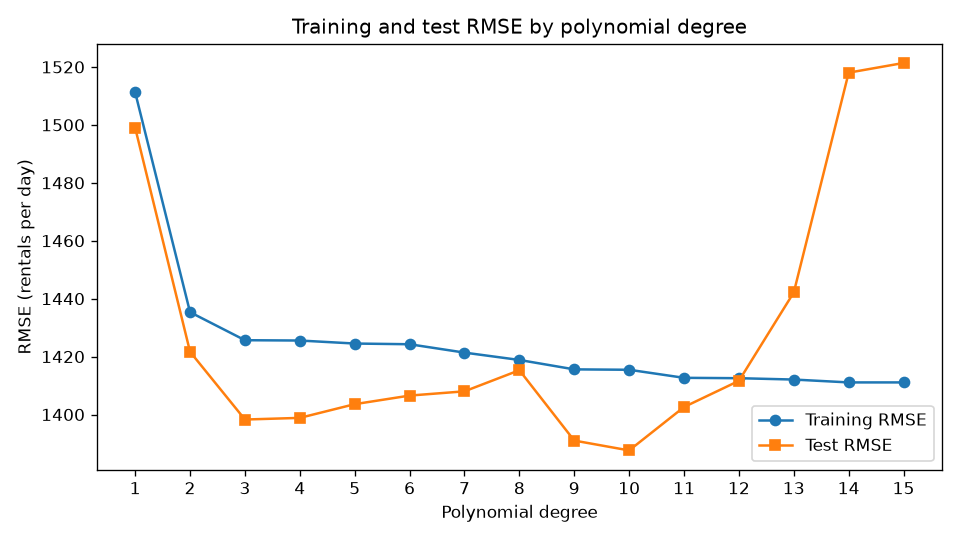

In [6]:
plt.figure(figsize=(8, 4.5))
plt.plot(results["Degree"], results["Training RMSE"], marker="o", label="Training RMSE")
plt.plot(results["Degree"], results["Test RMSE"], marker="s", label="Test RMSE")
plt.xticks(list(degrees))
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (rentals per day)")
plt.title("Training and test RMSE by polynomial degree")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
best_index = np.argmin(results["Test RMSE"].to_numpy())
best_degree = results["Degree"].iloc[best_index]
best_test_rmse = results["Test RMSE"].iloc[best_index]

print(f"Lowest observed test RMSE: {best_test_rmse:.2f} rentals per day (degree {best_degree})")

Lowest observed test RMSE: 1387.61 rentals per day (degree 10)


## 8. Discussion and conclusion

Training RMSE decreased at every degree, from 1,511.24 at degree 1 to 1,411.08 at degree 15. Most of the decrease occurred by degree 3. Each higher degree adds a term while retaining the terms available at lower degrees, so it can fit the training data at least as closely.

Test RMSE fell from 1,499.01 at degree 1 to 1,398.27 at degree 3, then fluctuated before reaching its minimum at degree 10. The early improvement on both sets suggests that the straight-line model underfits the temperature–rental relationship. After degree 10, test RMSE increased at every step, reaching 1,521.37 at degree 15 while training RMSE continued to fall. This pattern is evidence of overfitting at higher degrees on this split.

**Conclusion.** Degree 10 achieved the lowest observed test RMSE, 1,387.61 rentals per day. A temperature-only model gives the same prediction to days with the same temperature, even when their weather or working-day status differs. The assignment uses the test set to compare degrees, so the reported minimum is a model selection result from this split.

## 9. Execution instructions

1. In a terminal, change to the directory containing this notebook and the data folder. Install the dependencies.

   ```bash
   pip install numpy pandas matplotlib notebook
   ```

2. Start Jupyter Notebook from the same directory.

   ```bash
   jupyter notebook
   ```

3. Open **linear_regression.ipynb** and choose **Kernel → Restart Kernel and Run All Cells** to execute the cells in order. Save the notebook to retain the outputs. Once the dependencies are installed, the notebook runs offline using **data/day.csv**.